# Capstone — mirrors your deployed research paper

[![Open In Colab](https://colab.research.google.com/assets/colab-badge.svg)](https://colab.research.google.com/github/flyrank-bih/flyrank-ml-internship-starter/blob/main/work/notebooks/capstone.ipynb?flush_cache=true)

This skeleton is yours to fill. Work the sections **in order** — each one has a one-line hint. Simple words, honest numbers.

> Data note: everything below runs on the **public starter dataset** (`FlyRank/internship-starter`), not the gated full warehouse. Nothing here should be described as full-warehouse results.

In [ ]:
# Setup (run first). Installs are quiet; imports; one seed for everything.
%pip -q install pandas numpy scikit-learn matplotlib huggingface_hub

import json, shutil, zipfile
from pathlib import Path
from datetime import datetime, timezone

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display, Markdown

from huggingface_hub import hf_hub_download
from sklearn.compose import ColumnTransformer
from sklearn.impute import SimpleImputer
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import roc_auc_score, average_precision_score
from sklearn.model_selection import GroupShuffleSplit
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import OneHotEncoder, StandardScaler

SEED = 42
np.random.seed(SEED)
KS = [10, 20, 50, 100]
ARTIFACT_DIR = Path("capstone_artifacts")
ARTIFACT_DIR.mkdir(parents=True, exist_ok=True)

def fmt(v, d=3):
    return "n/a" if v is None else f"{v:.{d}f}"

## 1. Question

*The research question and the decision it supports.*

**Research question.** Among already-published content pages, which ones carry the observed signals (staleness, visibility, search position, content type) that most often go with a declining trend — so a human reviewer can look at those first?

**Decision it supports.** A content team has limited review time. This notebook produces a **ranked review queue** as decision-support. It does not trigger any action by itself.

**What the label means.** The label is an *observed snapshot proxy*: `trend_direction == "down"`. It is not a future outcome. So the question is about **association in the data**, not about predicting a decline or proving that a refresh causes recovery.

## 2. Data

*Which release, which tables, date windows, what you excluded and why. Public-safe.*

- **Release:** public starter dataset `FlyRank/internship-starter`, table `content_refresh_anonymized.csv`. The gated full warehouse is **not** used.
- **Date window:** the file reports 90-day impressions and a snapshot trend. It gives no calendar dates I can verify, so I make no date-window claim beyond "90d".
- **No rows dropped.** Missing or bad values are handled inside the model pipeline instead.
- **Excluded as model inputs:** `client_id`, `content_id` (identifiers), `trend_direction` (the label), `trend_pct` (the numeric twin of the label, so using it would be leakage).
- **Zero `avg_position`** is treated as "no data", not rank zero. A flag column keeps that information.
- **Public-safe:** only counts and aggregates are printed. No IDs, URLs or query text appear in any output.

In [ ]:
DATA_PATH = Path("content_refresh_anonymized.csv")

if not DATA_PATH.exists():
    try:
        downloaded = hf_hub_download(
            repo_id="FlyRank/internship-starter",
            repo_type="dataset",
            filename="content_refresh_anonymized.csv",
        )
    except Exception as e:
        raise RuntimeError(
            "Could not download the starter dataset. If it needs access, run "
            "`from huggingface_hub import login; login()` first, or upload the CSV "
            f"to {DATA_PATH.resolve()}. Original error: {e}"
        )
    shutil.copy2(downloaded, DATA_PATH)

df = pd.read_csv(DATA_PATH)

REQUIRED = [
    "client_id", "content_id", "trend_direction",
    "days_since_last_update", "impressions_90d",
    "ctr", "avg_position", "content_type",
]
missing_cols = sorted(set(REQUIRED) - set(df.columns))
if missing_cols:
    raise ValueError(f"Dataset schema mismatch. Missing columns: {missing_cols}")

# Convert numeric inputs and keep an honest audit of what was lost.
NUMERIC_SOURCE = ["days_since_last_update", "impressions_90d", "ctr", "avg_position"]
audit_rows = []
for col in NUMERIC_SOURCE:
    before = int(df[col].isna().sum())
    df[col] = pd.to_numeric(df[col], errors="coerce")
    audit_rows.append({"column": col, "missing_before": before, "missing_after": int(df[col].isna().sum())})
audit = pd.DataFrame(audit_rows)

N_ROWS, N_COLS = len(df), len(df.columns)
N_CLIENTS = int(df["client_id"].nunique())
N_ZERO_POS = int(df["avg_position"].eq(0).sum())

print(f"Rows: {N_ROWS:,} | Columns: {N_COLS} | Clients: {N_CLIENTS} | Content types: {df['content_type'].nunique()}")
print(f"Rows with avg_position == 0 (treated as no data): {N_ZERO_POS:,}")
print("\nMissing values before/after numeric conversion:")
display(audit)
print("trend_direction values:")
display(df["trend_direction"].value_counts(dropna=False).to_frame("rows"))
print("Numeric summary (no identifiers shown):")
display(df[NUMERIC_SOURCE].describe().T.round(3))

content_refresh_anonymized.csv:   0%|          | 0.00/8.23M [00:00<?, ?B/s]

Rows: 30,000 | Columns: 53 | Clients: 32 | Content types: 3
Rows with avg_position == 0 (treated as no data): 1,205

Missing values before/after numeric conversion:


,column,missing_before,missing_after
0,days_since_last_update,0,0
1,impressions_90d,0,0
2,ctr,0,0
3,avg_position,0,0


trend_direction values:


,rows
trend_direction,
down,16262
stable,5962
up,4388
new,2236
flat,1152


Numeric summary (no identifiers shown):


,count,mean,std,min,25%,50%,75%,max
days_since_last_update,30000.0,46.098,42.079,1.0,20.0,20.00,104.00,373.0
impressions_90d,30000.0,5200.366,16838.020,1.0,81.0,731.00,3615.25,517715.0
ctr,30000.0,0.511,3.279,0.0,0.0,0.07,0.29,100.0
avg_position,30000.0,16.342,15.217,0.0,6.2,10.80,22.30,245.0


## 3. Methodology

*Assumptions, features, label definition, baseline, validation design, leakage checks.*

- **Label:** `target = 1` when `trend_direction` is `"down"`, else `0`. Observed snapshot proxy.
- **Features:** days since last update, log of 90-day impressions (impressions are heavy-tailed), CTR, average position (zero → missing), a "position unavailable" flag, and content type.
- **Model:** logistic regression (readable, one coefficient per feature) behind an imputer + scaler + one-hot pipeline, so preprocessing is learned from training rows only.
- **Baseline:** a transparent hand-written rule score (visibility, staleness, position opportunity). It is a comparator, not a learned model.
- **Validation:** 80/20 split **by client** (`GroupShuffleSplit`), so no client appears in both train and test. Model and baseline are scored on the *same* held-out rows.
- **Leakage checks:** no ID/label columns in the features, zero client overlap, both classes present in each split.
- **Seed:** 42 everywhere.

In [ ]:
# --- label -------------------------------------------------------------
df["target"] = df["trend_direction"].astype(str).str.strip().str.lower().eq("down").astype(int)
assert df["target"].nunique() == 2, (
    "Label has one class only. Check the trend_direction values printed in section 2 "
    "(maybe 'down' is spelled differently)."
)

# --- feature engineering ----------------------------------------------
df["avg_position_no_data"] = (df["avg_position"].isna() | df["avg_position"].eq(0)).astype(int)
df["avg_position_model"] = df["avg_position"].mask(df["avg_position"].eq(0))
df["impressions_log1p"] = np.log1p(df["impressions_90d"].clip(lower=0))

NUMERIC = ["days_since_last_update", "impressions_log1p", "ctr",
           "avg_position_model", "avg_position_no_data"]
CATEGORICAL = ["content_type"]
FEATURES = NUMERIC + CATEGORICAL
FORBIDDEN = {"target", "trend_direction", "trend_pct", "client_id", "content_id"}

X = df[FEATURES].copy()
X["content_type"] = X["content_type"].astype("object")
y = df["target"]
groups = df["client_id"].astype(str)

# --- split by client ---------------------------------------------------
splitter = GroupShuffleSplit(n_splits=1, test_size=0.20, random_state=SEED)
train_idx, test_idx = next(splitter.split(X, y, groups=groups))
X_train, X_test = X.iloc[train_idx], X.iloc[test_idx]
y_train, y_test = y.iloc[train_idx], y.iloc[test_idx]
groups_train, groups_test = groups.iloc[train_idx], groups.iloc[test_idx]

leak_checks = pd.DataFrame([
    ("No ID or label columns in features", not (set(FEATURES) & FORBIDDEN)),
    ("No client appears in both train and test", set(groups_train).isdisjoint(set(groups_test))),
    ("Training split has both classes", y_train.nunique() == 2),
    ("Test split has both classes", y_test.nunique() == 2),
], columns=["check", "passed"])
display(leak_checks)
assert leak_checks.loc[:1, "passed"].all(), "Leakage check failed!"
assert y_train.nunique() == 2, "Training split has only one class."

N_TEST = int(len(test_idx))
N_TRAIN_CLIENTS = int(groups_train.nunique())
N_TEST_CLIENTS = int(groups_test.nunique())
BASE_RATE = float(y_test.mean())
print(f"Train rows: {len(train_idx):,} ({N_TRAIN_CLIENTS} clients) | Test rows: {N_TEST:,} ({N_TEST_CLIENTS} clients)")
print(f"Test base rate of observed 'down': {BASE_RATE:.3f}")

# --- model -------------------------------------------------------------
preprocess = ColumnTransformer([
    ("numeric", Pipeline([("imputer", SimpleImputer(strategy="median")),
                          ("scaler", StandardScaler())]), NUMERIC),
    ("categorical", Pipeline([("imputer", SimpleImputer(strategy="most_frequent")),
                              ("onehot", OneHotEncoder(handle_unknown="ignore"))]), CATEGORICAL),
])
model = Pipeline([
    ("preprocess", preprocess),
    ("classifier", LogisticRegression(max_iter=2000, random_state=SEED)),
])
model.fit(X_train, y_train)
model_scores = model.predict_proba(X_test)[:, 1]

# --- transparent rule baseline ----------------------------------------
def percentile_score(series, higher_is_better=True):
    s = pd.to_numeric(series, errors="coerce")
    if not higher_is_better:
        s = -s
    return s.rank(pct=True).fillna(0.5)

test_raw = df.iloc[test_idx].copy()
visibility = percentile_score(test_raw["impressions_90d"])
freshness_risk = percentile_score(test_raw["days_since_last_update"])
position_opportunity = percentile_score(
    test_raw["avg_position"].mask(test_raw["avg_position"].eq(0)), higher_is_better=False
)
baseline_scores = (
    0.45 * visibility
    + 0.30 * freshness_risk
    + 0.25 * (position_opportunity * visibility)
).to_numpy()
print("Model trained and baseline scored on the same held-out rows.")

,check,passed
0,No ID or label columns in features,True
1,No client appears in both train and test,True
2,Training split has both classes,True
3,Test split has both classes,True


Train rows: 23,837 (25 clients) | Test rows: 6,163 (7 clients)
Test base rate of observed 'down': 0.511
Model trained and baseline scored on the same held-out rows.


## 4. Results (vs baseline)

*Model vs baseline on the same split. The honest table.*

Precision@K = of the top K pages in the queue, the share that are observed `down`. The base rate is what you would get by picking pages at random, so a useful queue should sit above it.

In [ ]:
def precision_at_k(y_true, scores, k):
    y_arr, s_arr = np.asarray(y_true), np.asarray(scores)
    n = min(k, len(y_arr))
    if n == 0:
        return None
    top = np.argsort(-s_arr, kind="stable")[:n]   # stable = deterministic ties
    return float(y_arr[top].mean())

prec = {
    k: {"model": precision_at_k(y_test, model_scores, k),
        "rule": precision_at_k(y_test, baseline_scores, k)}
    for k in KS
}

results_table = pd.DataFrame([{
    "K": k,
    "Logistic regression": prec[k]["model"],
    "Rule baseline": prec[k]["rule"],
    "Base rate": BASE_RATE,
    "Model lift": prec[k]["model"] / BASE_RATE if BASE_RATE > 0 else None,
    "Rule lift": prec[k]["rule"] / BASE_RATE if BASE_RATE > 0 else None,
} for k in KS]).round(3)
display(results_table)

if y_test.nunique() == 2:
    AUC_M = float(roc_auc_score(y_test, model_scores))
    AP_M = float(average_precision_score(y_test, model_scores))
    AUC_R = float(roc_auc_score(y_test, baseline_scores))
    AP_R = float(average_precision_score(y_test, baseline_scores))
else:
    AUC_M = AP_M = AUC_R = AP_R = None

rank_metrics = pd.DataFrame({
    "Logistic regression": [AUC_M, AP_M],
    "Rule baseline": [AUC_R, AP_R],
}, index=["ROC-AUC", "Average precision"]).round(3)
display(rank_metrics)

# Dynamic, honest reading of the table.
p_m, p_r = prec[50]["model"], prec[50]["rule"]
if p_m is None or p_r is None:
    cmp_word = "could not be compared"
elif p_m > p_r:
    cmp_word = "higher than"
elif p_m < p_r:
    cmp_word = "lower than"
else:
    cmp_word = "the same as"

reading = (
    f"**Reading the table.** On {N_TEST_CLIENTS} held-out clients ({N_TEST:,} rows, observed base rate "
    f"{BASE_RATE:.1%}), the model's top 50 had an observed decline share of {fmt(p_m)}; "
    f"the rule baseline's top 50 had {fmt(p_r)}. The model figure is {cmp_word} the baseline at K=50."
)
if N_TEST_CLIENTS < 10:
    reading += (f" Only {N_TEST_CLIENTS} clients are held out and this is a single split, so treat the "
                "comparison as directional, not stable.")
display(Markdown(reading))

,K,Logistic regression,Rule baseline,Base rate,Model lift,Rule lift
0,10,0.30,0.50,0.511,0.587,0.979
1,20,0.25,0.40,0.511,0.489,0.783
2,50,0.34,0.28,0.511,0.665,0.548
3,100,0.37,0.32,0.511,0.724,0.626


,Logistic regression,Rule baseline
ROC-AUC,0.546,0.504
Average precision,0.522,0.487


**Reading the table.** On 7 held-out clients (6,163 rows, observed base rate 51.1%), the model's top 50 had an observed decline share of 0.340; the rule baseline's top 50 had 0.280. The model figure is higher than the baseline at K=50. Only 7 clients are held out and this is a single split, so treat the comparison as directional, not stable.

## 5. Limitations

*What this work cannot claim.*

- **Starter data only.** Not the gated full warehouse; results must not be described as full-warehouse results.
- **Proxy label.** `trend_direction == "down"` is an observed snapshot, not a future outcome. This work does not predict declines.
- **Same-window features.** CTR, impressions and position are measured in the same period as the label, so they may partly reflect the decline itself rather than precede it.
- **One split, few clients.** A single client-level split gives a noisy estimate. Another seed could change which method looks better.
- **Association only.** Nothing here shows that refreshing a page causes recovery, or says how Google ranks pages.
- **Baseline weights are hand-set.** The rule score is a reasonable comparator, not a tuned optimum.
- **Human review required.** The ranked queue is decision-support. A person decides what to do with each page.

## 6. Ranked recommendations

*The action playbook output — the paper's recommendations section.*

The queue below orders the held-out pages by model score. Identifiers are deliberately left out, so this table is safe to publish.

In [ ]:
ranked = test_raw.copy()
ranked["model_score"] = model_scores
ranked["baseline_score"] = baseline_scores
ranked["observed_down"] = y_test.to_numpy()
ranked["rank"] = ranked["model_score"].rank(method="first", ascending=False).astype(int)
ranked["priority_tier"] = pd.cut(
    ranked["rank"], bins=[0, 10, 50, np.inf],
    labels=["P1_top_10", "P2_top_50", "P3_remaining"],
)

# Reason codes: thresholds come from TRAINING rows only.
impr_median = df.iloc[train_idx]["impressions_90d"].median()
stale = ranked["days_since_last_update"].ge(90).to_numpy()
high_vis = ranked["impressions_90d"].gt(impr_median).to_numpy()
no_pos = ranked["avg_position_no_data"].eq(1).to_numpy()

codes = []
for s, h, n in zip(stale, high_vis, no_pos):
    r = []
    if s: r.append("stale_90d_plus")
    if h: r.append("above_median_impressions")
    if n: r.append("position_data_unavailable")
    codes.append(";".join(r) if r else "review_model_signals")
ranked["reason_codes"] = codes

public_queue = ranked.sort_values("rank")[
    ["rank", "priority_tier", "model_score", "baseline_score", "reason_codes"]
].copy()
public_queue[["model_score", "baseline_score"]] = public_queue[["model_score", "baseline_score"]].round(4)

print("Top 20 of the ranked review queue (no identifiers):")
display(public_queue.head(20))

tier_summary = (
    ranked.groupby("priority_tier", observed=True)
    .agg(pages=("rank", "size"), observed_down_share=("observed_down", "mean"))
    .round(3)
)
print("Observed decline share by priority tier (aggregate only):")
display(tier_summary)

reason_counts = (
    pd.Series([c for row in codes for c in row.split(";")])
    .value_counts().rename("pages").to_frame()
)
print("How often each reason code appears in the queue:")
display(reason_counts)

Top 20 of the ranked review queue (no identifiers):


,rank,priority_tier,model_score,baseline_score,reason_codes
6653,1,P1_top_10,0.7432,0.9534,stale_90d_plus;above_median_impressions
21565,2,P1_top_10,0.7334,0.9710,stale_90d_plus;above_median_impressions
17400,3,P1_top_10,0.7236,0.9634,stale_90d_plus;above_median_impressions
23446,4,P1_top_10,0.7233,0.9281,stale_90d_plus;above_median_impressions
26384,5,P1_top_10,0.7214,0.9544,stale_90d_plus;above_median_impressions
26564,6,P1_top_10,0.7208,0.9409,stale_90d_plus;above_median_impressions
29716,7,P1_top_10,0.7205,0.9256,stale_90d_plus;above_median_impressions
2365,8,P1_top_10,0.7159,0.9476,stale_90d_plus;above_median_impressions
19645,9,P1_top_10,0.7135,0.9355,stale_90d_plus;above_median_impressions
4495,10,P1_top_10,0.7134,0.9587,stale_90d_plus;above_median_impressions


Observed decline share by priority tier (aggregate only):


,pages,observed_down_share
priority_tier,,
P1_top_10,10,0.300
P2_top_50,40,0.350
P3_remaining,6113,0.512


How often each reason code appears in the queue:


,pages
review_model_signals,2791
above_median_impressions,2565
stale_90d_plus,1218
position_data_unavailable,62


### Action playbook (decision-support)

| Tier | Who goes here | Suggested reviewer action |
|---|---|---|
| **P1 — top 10** | Highest model scores | Review first. Check whether the page is out of date, whether its topic still matches what people search for, and whether a refresh is worth the effort. |
| **P2 — ranks 11–50** | Next group | Review in the same cycle if time allows. Use the reason codes to see what stands out (stale, high visibility, missing position data). |
| **P3 — remaining** | Everything else | No action by default. Re-score on the next data refresh. |

**How to use it carefully.** The reason codes describe what is *observed* about a page; they are not proven causes. A reviewer should confirm each page by hand before changing it, and track results afterwards, because this work cannot say that a refresh will help.

## 7. Artifacts the paper embeds

*Generate/collect the charts and tables your deployed page will show.*

This cell saves: the results table, the metrics JSON, the Precision@K chart, a coefficient chart (which signals the readable model leans on), the public ranked queue and a short run summary. Everything is zipped for download.

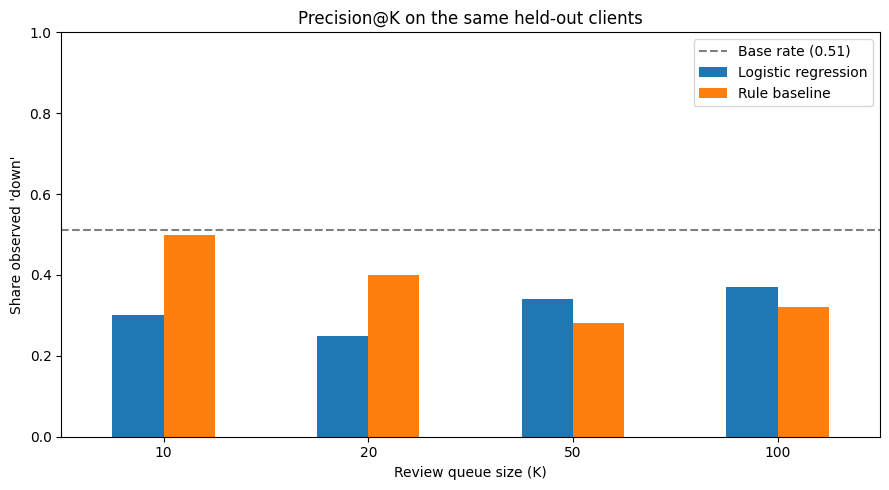

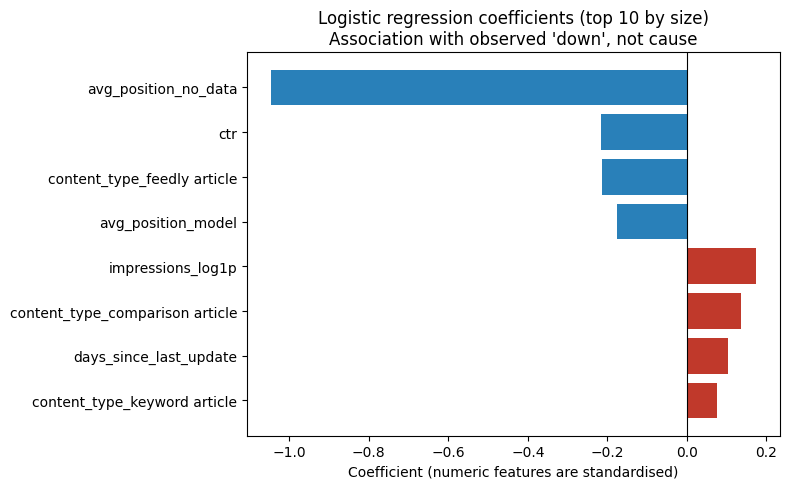

Public-safety scan passed: no identifier columns, no URLs in saved text artifacts.
Saved: ['capstone_metrics.json', 'model_coefficients.png', 'precision_at_k.png', 'ranked_review_recommendations.csv', 'results_table.csv', 'run_summary.md', 'tier_summary.csv']


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

In [ ]:
# --- Chart 1: Precision@K vs baseline ---------------------------------
chart_df = results_table[["K", "Logistic regression", "Rule baseline"]]
ax = chart_df.plot(x="K", y=["Logistic regression", "Rule baseline"], kind="bar", figsize=(9, 5))
ax.axhline(BASE_RATE, color="gray", linestyle="--", label=f"Base rate ({BASE_RATE:.2f})")
ax.legend()
ax.set_title("Precision@K on the same held-out clients")
ax.set_xlabel("Review queue size (K)")
ax.set_ylabel("Share observed 'down'")
ax.set_ylim(0, 1)
plt.xticks(rotation=0)
plt.tight_layout()
plt.savefig(ARTIFACT_DIR / "precision_at_k.png", dpi=160)
plt.show()

# --- Chart 2: what the readable model leans on ------------------------
names = model.named_steps["preprocess"].get_feature_names_out()
coefs = model.named_steps["classifier"].coef_[0]
coef_df = pd.DataFrame({"feature": names, "coefficient": coefs})
coef_df["feature"] = coef_df["feature"].str.replace(r"^(numeric|categorical)__", "", regex=True)
top = coef_df.reindex(coef_df["coefficient"].abs().sort_values(ascending=False).index).head(10).iloc[::-1]
plt.figure(figsize=(8, 5))
plt.barh(top["feature"], top["coefficient"], color=["#c0392b" if c > 0 else "#2980b9" for c in top["coefficient"]])
plt.axvline(0, color="black", linewidth=0.8)
plt.title("Logistic regression coefficients (top 10 by size)\nAssociation with observed 'down', not cause")
plt.xlabel("Coefficient (numeric features are standardised)")
plt.tight_layout()
plt.savefig(ARTIFACT_DIR / "model_coefficients.png", dpi=160)
plt.show()

# --- Tables and metrics ------------------------------------------------
results_table.to_csv(ARTIFACT_DIR / "results_table.csv", index=False)
public_queue.to_csv(ARTIFACT_DIR / "ranked_review_recommendations.csv", index=False)
tier_summary.to_csv(ARTIFACT_DIR / "tier_summary.csv")

metrics = {
    "dataset": "FlyRank/internship-starter (public starter, not the gated warehouse)",
    "dataset_rows": int(N_ROWS),
    "test_rows": N_TEST,
    "train_clients": N_TRAIN_CLIENTS,
    "test_clients": N_TEST_CLIENTS,
    "client_overlap": int(len(set(groups_train) & set(groups_test))),
    "seed": SEED,
    "split": "80/20 GroupShuffleSplit by client_id",
    "label": "trend_direction == down (observed snapshot proxy)",
    "feature_columns": FEATURES,
    "test_base_rate": BASE_RATE,
    "roc_auc": {"logistic_regression": AUC_M, "rule_baseline": AUC_R},
    "average_precision": {"logistic_regression": AP_M, "rule_baseline": AP_R},
    "precision_at_k": {str(k): {"logistic_regression": prec[k]["model"], "rule_baseline": prec[k]["rule"]} for k in KS},
    "run_utc": datetime.now(timezone.utc).isoformat(),
    "limitations": [
        "Starter dataset only.",
        "Label is an observed snapshot proxy, not a future outcome.",
        "Features are measured in the same window as the label.",
        "Single client-level split; high variance with few clients.",
        "Association only; no causal claim.",
        "Recommendations need human review.",
    ],
}
assert metrics["client_overlap"] == 0
(ARTIFACT_DIR / "capstone_metrics.json").write_text(json.dumps(metrics, indent=2), encoding="utf-8")

summary_lines = [
    "# FlyRank Capstone - run summary", "",
    f"- Run time (UTC): {metrics['run_utc']}",
    f"- Dataset: public starter, {N_ROWS:,} rows, {N_CLIENTS} clients",
    f"- Held-out: {N_TEST:,} rows from {N_TEST_CLIENTS} clients; client overlap {metrics['client_overlap']}",
    f"- Test base rate (observed 'down'): {BASE_RATE:.3f}",
    f"- ROC-AUC model / rule: {fmt(AUC_M)} / {fmt(AUC_R)}",
    f"- Average precision model / rule: {fmt(AP_M)} / {fmt(AP_R)}", "",
    "## Precision@K", "",
    "| K | Logistic regression | Rule baseline | Base rate |",
    "|---:|---:|---:|---:|",
] + [f"| {k} | {fmt(prec[k]['model'])} | {fmt(prec[k]['rule'])} | {BASE_RATE:.3f} |" for k in KS] + [
    "", "## Interpretation boundary", "",
    "Ranks pages by association with an observed decline proxy. It does not predict a "
    "proven future outcome, show how Google ranks pages, or show that a refresh causes recovery. "
    "Starter dataset only. Review recommendations manually before acting on them.",
]
(ARTIFACT_DIR / "run_summary.md").write_text("\n".join(summary_lines), encoding="utf-8")

# --- Public-safety scan ------------------------------------------------
pub_cols = set(pd.read_csv(ARTIFACT_DIR / "ranked_review_recommendations.csv").columns)
assert not (pub_cols & {"client_id", "content_id", "url", "query"}), "Identifier column in public queue!"
for p in ARTIFACT_DIR.glob("*"):
    if p.suffix in {".md", ".json", ".csv"}:
        txt = p.read_text(encoding="utf-8").lower()
        assert "http" not in txt, f"URL found in {p.name}"
print("Public-safety scan passed: no identifier columns, no URLs in saved text artifacts.")

# --- Package -----------------------------------------------------------
zip_path = Path("capstone_artifacts.zip")
with zipfile.ZipFile(zip_path, "w", zipfile.ZIP_DEFLATED) as zf:
    for f in sorted(ARTIFACT_DIR.iterdir()):
        zf.write(f, arcname=f.name)
print("Saved:", sorted(p.name for p in ARTIFACT_DIR.iterdir()))
try:
    from google.colab import files
    files.download(str(zip_path))
except ImportError:
    print("Not in Colab; zip is at", zip_path.resolve())

## Self-check

Before you submit, confirm each line honestly:

- [ ] Every section above is filled — markdown thinking AND the code that backs it
- [ ] The notebook runs top to bottom with no errors (Runtime → Run all)
- [ ] No client names, URLs, or private queries anywhere
- [ ] My claims use careful words: observed, measured, directional, decision-support
- [ ] Committed to my repo under `work/notebooks/` — then submit your repo URL on the card. Done.
- [ ] My deployed paper has **all 9 sections** — including the **Abstract** at the top and **Acknowledgments & data credit** (the https://flyrank.ai link) at the bottom.
- [ ] **ML-12 done in this notebook's closing cells:** 5-minute demo outline + a social-post cut + a 3-sentence employer-facing summary.

## ML-12 — Ship it: demo, social post, employer summary

The three cells below are filled from this run's real numbers, so they stay honest if you re-run. Edit the wording to sound like you.

In [ ]:
# ML-12 (a): 5-minute demo outline
demo_outline = f"""### 5-minute demo outline

**0:00-0:30 | The question.** A content team can only review so many pages. Which ones should they look at first? I rank pages by observed signals that go with a declining trend.

**0:30-1:15 | The data.** Public starter dataset: {N_ROWS:,} pages across {N_CLIENTS} clients. Not the full warehouse. Label = observed "down" trend, a snapshot proxy, not a future outcome.

**1:15-2:15 | The method.** Readable logistic regression vs a transparent rule score. Split by client ({N_TRAIN_CLIENTS} train / {N_TEST_CLIENTS} held out), so the model is judged on clients it never saw. Leakage checks: no IDs or label twins in the features, zero client overlap.

**2:15-3:30 | The result.** Show the Precision@K chart. In the model's top 50, the observed decline share was {fmt(prec[50]['model'])} vs {fmt(prec[50]['rule'])} for the rule baseline and {BASE_RATE:.2f} overall. Say plainly if the model does not clearly beat the baseline.

**3:30-4:15 | The queue.** Show the top of the ranked queue and the P1/P2/P3 tiers with reason codes. A person reviews each page; nothing happens automatically.

**4:15-5:00 | Limits and next step.** Proxy label, same-window features, one split, association only. Next: re-run on the full warehouse, add a time-based split, and test whether reviewed pages actually recover.
"""
display(Markdown(demo_outline))
(ARTIFACT_DIR / "ml12_demo_outline.md").write_text(demo_outline, encoding="utf-8")

### 5-minute demo outline

**0:00-0:30 | The question.** A content team can only review so many pages. Which ones should they look at first? I rank pages by observed signals that go with a declining trend.

**0:30-1:15 | The data.** Public starter dataset: 30,000 pages across 32 clients. Not the full warehouse. Label = observed "down" trend, a snapshot proxy, not a future outcome.

**1:15-2:15 | The method.** Readable logistic regression vs a transparent rule score. Split by client (25 train / 7 held out), so the model is judged on clients it never saw. Leakage checks: no IDs or label twins in the features, zero client overlap.

**2:15-3:30 | The result.** Show the Precision@K chart. In the model's top 50, the observed decline share was 0.340 vs 0.280 for the rule baseline and 0.51 overall. Say plainly if the model does not clearly beat the baseline.

**3:30-4:15 | The queue.** Show the top of the ranked queue and the P1/P2/P3 tiers with reason codes. A person reviews each page; nothing happens automatically.

**4:15-5:00 | Limits and next step.** Proxy label, same-window features, one split, association only. Next: re-run on the full warehouse, add a time-based split, and test whether reviewed pages actually recover.


1238

In [ ]:
# ML-12 (b): social-post cut
better = prec[50]["model"] is not None and prec[50]["rule"] is not None and prec[50]["model"] > prec[50]["rule"]
social_post = (
    "I built a small, honest ML project for FlyRank: ranking content pages that are worth a human refresh review.\n\n"
    f"On clients the model never saw, its top-50 list had an observed decline share of {fmt(prec[50]['model'], 2)} "
    f"vs {BASE_RATE:.2f} overall"
    + (f" and {fmt(prec[50]['rule'], 2)} for a simple rule baseline." if better else
       f", and {fmt(prec[50]['rule'], 2)} for a simple rule baseline - so the model does not clearly beat the baseline yet, and I say so in the write-up.")
    + "\n\nBiggest lesson: the label is only an observed snapshot, so this is decision-support, not prediction or proof that a refresh works.\n\n"
    "Public starter data, split by client, leakage-checked, all numbers reproducible (seed 42).\n"
    "Paper + notebook: [add your paper link here]\n"
    "#MachineLearning #DataScience #SEO"
)
print(social_post)
(ARTIFACT_DIR / "ml12_social_post.txt").write_text(social_post, encoding="utf-8")

I built a small, honest ML project for FlyRank: ranking content pages that are worth a human refresh review.

On clients the model never saw, its top-50 list had an observed decline share of 0.34 vs 0.51 overall and 0.28 for a simple rule baseline.

Biggest lesson: the label is only an observed snapshot, so this is decision-support, not prediction or proof that a refresh works.

Public starter data, split by client, leakage-checked, all numbers reproducible (seed 42).
Paper + notebook: [add your paper link here]
#MachineLearning #DataScience #SEO


552

In [ ]:
# ML-12 (c): 3-sentence employer-facing summary
employer_summary = (
    f"I built a reproducible, leakage-checked ranking of content pages that most merit a refresh review, "
    f"using a public starter dataset of {N_ROWS:,} pages across {N_CLIENTS} clients. "
    f"On {N_TEST_CLIENTS} clients held out from training, its top-50 list showed an observed decline share of "
    f"{fmt(prec[50]['model'], 2)} against a {BASE_RATE:.2f} overall base rate and {fmt(prec[50]['rule'], 2)} for a transparent rule-based baseline. "
    "I documented the limits plainly (proxy label, single split, association only) so the output works as decision-support for a human reviewer, not an automatic decision."
)
display(Markdown(employer_summary))
(ARTIFACT_DIR / "ml12_employer_summary.txt").write_text(employer_summary, encoding="utf-8")

I built a reproducible, leakage-checked ranking of content pages that most merit a refresh review, using a public starter dataset of 30,000 pages across 32 clients. On 7 clients held out from training, its top-50 list showed an observed decline share of 0.34 against a 0.51 overall base rate and 0.28 for a transparent rule-based baseline. I documented the limits plainly (proxy label, single split, association only) so the output works as decision-support for a human reviewer, not an automatic decision.

506

## Acknowledgments & data credit

Data: FlyRank public internship starter dataset (`FlyRank/internship-starter`), anonymized. Thanks to the FlyRank team for the starter materials. https://flyrank.ai